# 🌫️ Reworked Urban Wildfire Smoke `PM2.5` Benchmark (Hourly, Plume-Onset Aligned)

### Data Sources
- **Hourly Ground `PM2.5` & Station Site Metadata:** [U.S. EPA Air Quality System (`AQS` `hourly_88101` + `aqs_sites`)](https://aqs.epa.gov/aqsweb/airdata/download_files.html)
- **Hourly Planetary Boundary Layer Height, Wind Vector & Meteorology:** [Open-Meteo ERA5 Reanalysis Archive](https://open-meteo.com/en/docs/historical-weather-api)
- **Hourly Smoke Aerosol Optical Depth (`AOD`) & Co-Pollutants:** [Open-Meteo CAMS Air Quality Archive](https://open-meteo.com/en/docs/air-quality-api)

### Benchmark Design Highlights
1. **Smoke Arrival Onset ($\tau = 0$):** Anchored when clean background air (`[-72h, -1h]` max `<= 25`, median `<= 15` ug/m^3) crosses `PM2.5 >= 25 ug/m^3`, then sustains a true multi-hour wildfire plume (`post_peak >= 55 ug/m^3`, `>= 12h >= 25 ug/m^3`, excluding July 3–6 fireworks). Median peak occurs at **`tau = +23h`**.
2. **True `past_future` Dispersion & Smoke Forcing:** Forecasted columnar **`aerosol_optical_depth`**, **`boundary_layer_height_m`**, **`smoke_trapping_index`**, **`wind_ms`**, **`wind_dir_sin`/`cos`**, **`rain_mm_hr`**, and **`local_hour`** directly explain overhead smoke transport, inversion trapping, and wash-out dilution.
3. **100% Unique Stations & Chronological Split:** **`N = 439` unique US EPA stations** (`Train = 358` in `2022–2023`, `Test = 81` in `2024`, `0%` shared monitor IDs, `> 7`-month chronological separation).

### 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

### 2. Load Full Dataset, Summary & Feature Inventory

In [2]:
npz_path = 'data/reworked_wildfire_smoke_hourly.npz'
meta_path = 'data/reworked_wildfire_smoke_metadata.csv'

data = np.load(npz_path, allow_pickle=True)
meta = pd.read_csv(meta_path)

past_names = [str(x) for x in data['past_feature_names']]
pf_names = [str(x) for x in data['past_future_feature_names']]
static_names = [str(x) for x in data['static_feature_names']]
tau_steps = data['tau_steps']
ts_grid = data['timestamps_utc']

print(f'Samples (N):           {len(meta)} unique EPA sites')
print(f'Hours per sample (T):  {len(tau_steps)} (tau from {tau_steps[0]} to {tau_steps[-1]} hours)')
print(f'Past covariates:       {len(past_names)} -> {past_names}')
print(f'Past-future covs:      {len(pf_names)} -> {pf_names}')
print(f'Static features:       {len(static_names)} -> {static_names}')

X_past = data['past_covariates']
X_pf = data['past_future_covariates']
X_static = data['static_features']
N, T, _ = X_past.shape

full_dict = {
    'sample_id': np.repeat(meta['sample_id'].values, T),
    'site_id': np.repeat(meta['site_id'].values, T),
    'city': np.repeat(meta['city'].values, T),
    'state': np.repeat(meta['state'].values, T),
    'split': np.repeat(meta['split'].values, T),
    'onset_utc': np.repeat(meta['onset_utc'].values, T),
    'timestamp_utc': ts_grid.reshape(-1),
    'tau_hour': np.tile(tau_steps, N),
}
for i, col in enumerate(static_names):
    vals = np.repeat(X_static[:, i], T)
    full_dict[col] = vals.astype(int) if col == 'setting_code' else vals
for i, col in enumerate(past_names):
    full_dict[col] = X_past[:, :, i].reshape(-1)
for i, col in enumerate(pf_names):
    full_dict[col] = X_pf[:, :, i].reshape(-1)

full_df = pd.DataFrame(full_dict)
print(f'\nFlattened full table shape: {full_df.shape}')
display(meta.head())
display(full_df[past_names + pf_names].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Samples (N):           439 unique EPA sites
Hours per sample (T):  145 (tau from -72 to 72 hours)
Past covariates:       8 -> ['pm25_ug_m3', 'pm25_rolling_mean_6h', 'pm25_change_1h', 'pm10_cams_ug_m3', 'co_ug_m3', 'ozone_ug_m3', 'no2_ug_m3', 'dust_ug_m3']
Past-future covs:      11 -> ['aerosol_optical_depth', 'boundary_layer_height_m', 'wind_ms', 'wind_dir_sin', 'wind_dir_cos', 'temp_c', 'apparent_temp_c', 'humidity_pct', 'pressure_hpa', 'rain_mm_hr', 'local_hour']
Static features:       4 -> ['latitude', 'longitude', 'elevation_m', 'setting_code']

Flattened full table shape: (63655, 31)


,sample_id,site_id,city,state,split,onset_utc,window_start_utc,window_end_utc,baseline_median_pm25,post_peak_pm25,post_peak_tau_hour,peak_aod,latitude,longitude,elevation_m,setting
0,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 05:00:00,2022-08-16 05:00:00,3.50,136.00,51,0.17,40.5501,-122.3809,149.0,SUBURBAN
1,1,06-103-0007,Red Bluff,California,train,2022-08-14 13:00:00,2022-08-11 13:00:00,2022-08-17 13:00:00,5.00,82.00,46,0.19,40.1709,-122.2556,100.0,SUBURBAN
2,2,06-073-1014,Otay Mesa,California,train,2022-08-31 10:00:00,2022-08-28 10:00:00,2022-09-03 10:00:00,9.10,83.85,26,0.21,32.5782,-116.9214,199.0,RURAL
3,3,30-049-0004,Not in a City,Montana,train,2022-09-04 04:00:00,2022-09-01 04:00:00,2022-09-07 04:00:00,11.05,99.30,29,0.66,46.8505,-111.9872,1194.0,RURAL
4,4,30-027-0006,Not in a City,Montana,train,2022-09-04 08:00:00,2022-09-01 08:00:00,2022-09-07 08:00:00,11.05,80.70,32,0.79,47.0485,-109.4553,1253.0,RURAL


,count,mean,std,min,50%,max
pm25_ug_m3,63655.0,23.80,32.64,0.00,11.60,675.85
pm25_rolling_mean_6h,63655.0,23.47,30.68,0.00,11.67,442.33
pm25_change_1h,63655.0,0.13,9.56,-496.00,0.00,460.00
pm10_cams_ug_m3,63655.0,27.13,23.62,0.40,19.70,357.60
co_ug_m3,63655.0,262.41,150.11,77.00,216.00,2656.00
ozone_ug_m3,63655.0,85.00,32.92,0.00,83.00,280.00
no2_ug_m3,63655.0,7.62,9.59,0.00,4.40,112.00
dust_ug_m3,63655.0,1.98,13.06,0.00,0.00,419.00
aerosol_optical_depth,63655.0,0.41,0.40,0.01,0.29,3.61
boundary_layer_height_m,63655.0,661.80,719.48,10.00,395.00,5210.00


### 3. Derived Feature Evaluation & Correlation Matrix (Justifying Redundancy Removal)

Highly correlated feature pairs (|r| > 0.90):
  - pm25_ug_m3                 vs pm25_rolling_mean_6h      : r = +0.921
  - temp_c                     vs apparent_temp_c           : r = +0.947

Derived feature correlations with primary target (pm25_ug_m3):
  - pm25_change_1h             vs pm25_ug_m3: r = +0.166
  - smoke_trapping_index       vs pm25_ug_m3: r = +0.308


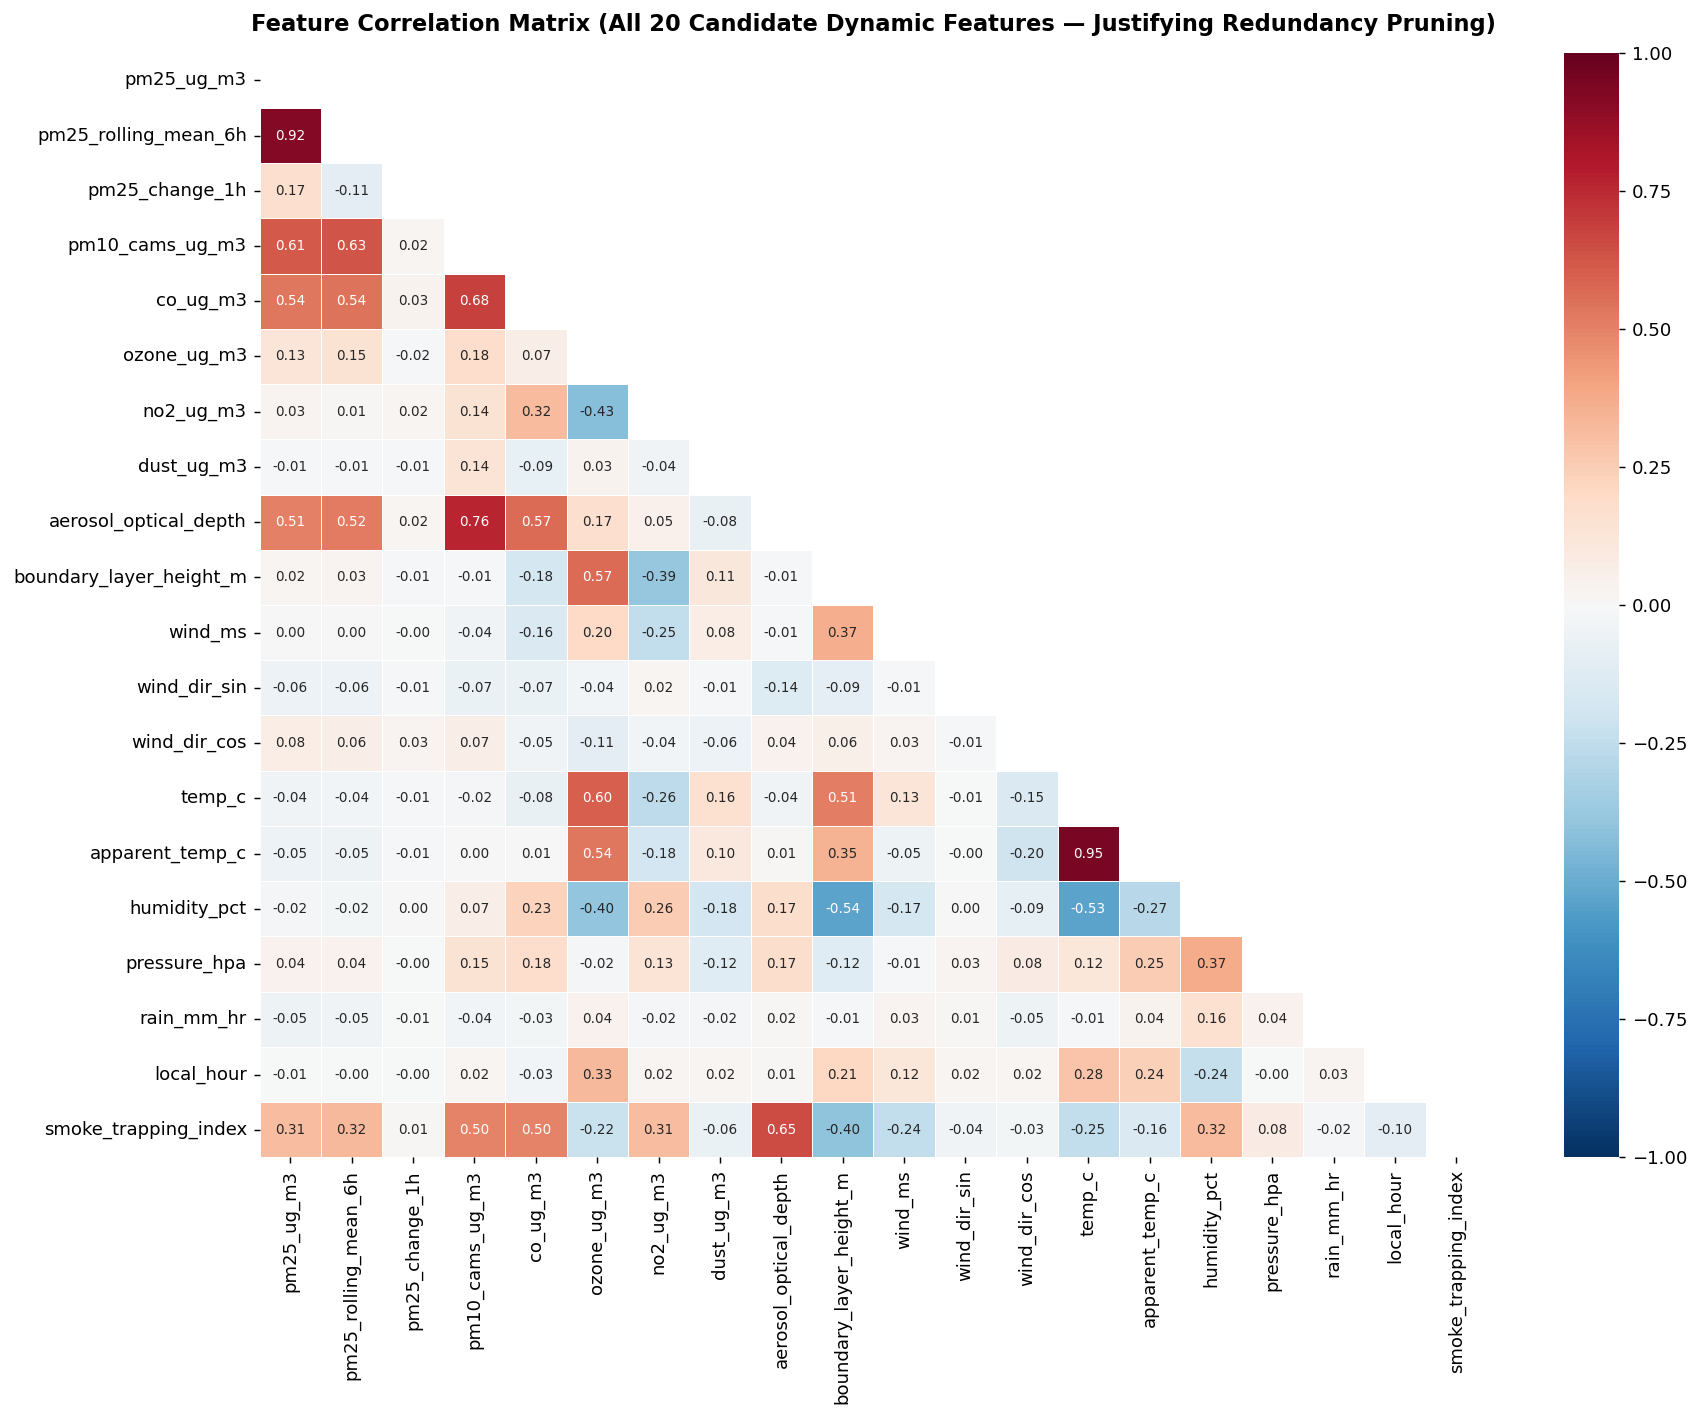

In [3]:
# Engineer boundary-layer smoke trapping proxy: overhead column AOD / PBL height (km + 0.1 offset)
# Connects satellite/CAMS smoke load (AOD) with shallow inversion trapping near the surface
full_df['smoke_trapping_index'] = full_df['aerosol_optical_depth'] / (full_df['boundary_layer_height_m'] / 1000.0 + 0.1)

all_candidate_features = past_names + pf_names + ['smoke_trapping_index']
corr = full_df[all_candidate_features].corr()

print('Highly correlated feature pairs (|r| > 0.90):')
for i in range(len(all_candidate_features)):
    for j in range(i + 1, len(all_candidate_features)):
        val = corr.iloc[i, j]
        if abs(val) > 0.90:
            print(f'  - {all_candidate_features[i]:26s} vs {all_candidate_features[j]:26s}: r = {val:+.3f}')

print('\nDerived feature correlations with primary target (pm25_ug_m3):')
for dcol in ['pm25_change_1h', 'smoke_trapping_index']:
    print(f'  - {dcol:26s} vs pm25_ug_m3: r = {corr.loc[dcol, "pm25_ug_m3"]:+.3f}')

fig, ax = plt.subplots(figsize=(14, 11), dpi=130)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={'size': 7.5},
    ax=ax,
)
ax.set_title(
    'Feature Correlation Matrix (All 20 Candidate Dynamic Features — Justifying Redundancy Pruning)',
    fontsize=12.5,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.savefig('data/wildfire_smoke_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Create Clean Non-Redundant Simple Dataset (`data/wildfire_smoke_simple.csv`)

In [4]:
# Drop the 2 redundant variables where |r| > 0.90:
#   - pm25_rolling_mean_6h (r=+0.926 vs pm25_ug_m3)
#   - apparent_temp_c (r=+0.942 vs temp_c)
REDUNDANT_TO_DROP = [
    'pm25_rolling_mean_6h',
    'apparent_temp_c',
]

KEEP_META = ['sample_id', 'site_id', 'city', 'state', 'split', 'onset_utc', 'timestamp_utc', 'tau_hour']
KEEP_STATIC = static_names
KEEP_PAST = [c for c in past_names if c not in REDUNDANT_TO_DROP]
KEEP_PF = [c for c in pf_names + ['smoke_trapping_index'] if c not in REDUNDANT_TO_DROP]

simple_df = full_df[KEEP_META + KEEP_STATIC + KEEP_PAST + KEEP_PF].copy()
simple_df['local_hour'] = simple_df['local_hour'].astype(int)

kept_dyn = KEEP_PAST + KEEP_PF
kept_corr = simple_df[kept_dyn].corr().copy()
np.fill_diagonal(kept_corr.values, 0.0)
max_r = float(kept_corr.abs().max().max())

X_std = (simple_df[kept_dyn] - simple_df[kept_dyn].mean()) / simple_df[kept_dyn].std()
vifs = dict(zip(kept_dyn, np.diag(np.linalg.inv(np.corrcoef(X_std.values, rowvar=False)))))

print(f'Dropped {len(REDUNDANT_TO_DROP)} redundant features: {REDUNDANT_TO_DROP}')
print(f'Max off-diagonal |r| among {len(kept_dyn)} kept dynamic features: {max_r:.3f}')
print(f'Max VIF across kept dynamic features: {max(vifs.values()):.2f} ({max(vifs, key=vifs.get)})')
assert simple_df.isna().sum().sum() == 0, 'Unexpected NaNs found!'

simple_csv_path = 'data/wildfire_smoke_simple.csv'
simple_df.to_csv(simple_csv_path, index=False)
print(f'Saved: {simple_csv_path} ({os.path.getsize(simple_csv_path) / (1024**2):.2f} MB), shape={simple_df.shape}')
display(simple_df.head())

Dropped 2 redundant features: ['pm25_rolling_mean_6h', 'apparent_temp_c']
Max off-diagonal |r| among 18 kept dynamic features: 0.760
Max VIF across kept dynamic features: 4.15 (pm10_cams_ug_m3)


Saved: data/wildfire_smoke_simple.csv (13.21 MB), shape=(63655, 30)


,sample_id,site_id,city,state,split,onset_utc,timestamp_utc,tau_hour,latitude,longitude,elevation_m,setting_code,pm25_ug_m3,pm25_change_1h,pm10_cams_ug_m3,co_ug_m3,ozone_ug_m3,no2_ug_m3,dust_ug_m3,aerosol_optical_depth,boundary_layer_height_m,wind_ms,wind_dir_sin,wind_dir_cos,temp_c,humidity_pct,pressure_hpa,rain_mm_hr,local_hour,smoke_trapping_index
0,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 05:00:00,-72,40.550129,-122.38092,149.0,2,1.0,-2.0,5.9,113.0,79.0,3.1,0.0,0.03,830.0,3.41,-0.052336,-0.998630,28.299999,19.0,983.099976,0.0,21,0.032258
1,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 06:00:00,-71,40.550129,-122.38092,149.0,2,3.0,2.0,5.9,114.0,69.0,3.5,0.0,0.03,730.0,0.94,-0.848048,-0.529919,25.400000,25.0,983.799988,0.0,22,0.036145
2,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 07:00:00,-70,40.550129,-122.38092,149.0,2,2.0,-1.0,6.3,115.0,64.0,3.8,0.0,0.02,630.0,0.92,-0.974370,-0.224951,23.400000,32.0,984.400024,0.0,23,0.027397
3,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 08:00:00,-69,40.550129,-122.38092,149.0,2,0.0,-2.0,6.9,115.0,60.0,3.9,0.0,0.02,555.0,1.70,0.766044,-0.642788,23.200001,34.0,985.000000,0.0,0,0.030534
4,0,06-089-0004,Redding,California,train,2022-08-13 05:00:00,2022-08-10 09:00:00,-68,40.550129,-122.38092,149.0,2,2.0,2.0,7.4,117.0,56.0,4.1,0.0,0.03,495.0,1.30,0.529919,-0.848048,21.900000,38.0,985.200012,0.0,1,0.050420


### 5. Feature Inventory: Past-Only vs. Past-Future vs. Static

In [5]:
DESC = {
    'sample_id': 'Integer event ID (0..438)',
    'site_id': 'Unique EPA AQS station ID (SS-CCC-NNNN)',
    'city': 'Monitor city name',
    'state': 'US State',
    'split': 'Chronological split (train: 2022-2023 / test: 2024)',
    'onset_utc': 'Smoke plume arrival onset UTC timestamp (tau=0)',
    'timestamp_utc': 'Hourly UTC timestamp',
    'tau_hour': 'Hours relative to smoke arrival (-72 to +72)',
    'latitude': 'EPA station latitude (deg N)',
    'longitude': 'EPA station longitude (deg E)',
    'elevation_m': 'Monitor elevation (meters above sea level)',
    'setting_code': 'EPA setting code (1=Urban Center, 2=Suburban, 3=Rural)',
    'pm25_ug_m3': '[TARGET] Hourly ground-truth EPA PM2.5 (ug/m^3)',
    'pm25_change_1h': '1-hour PM2.5 concentration rate of change (ug/m^3/hr)',
    'pm10_cams_ug_m3': 'Coarse particulate matter PM10 (ug/m^3, CAMS)',
    'co_ug_m3': 'Carbon monoxide combustion tracer (ug/m^3, CAMS)',
    'ozone_ug_m3': 'Ground-level ozone O3 (ug/m^3, CAMS)',
    'no2_ug_m3': 'Nitrogen dioxide urban combustion tracer (ug/m^3, CAMS)',
    'dust_ug_m3': 'Mineral dust concentration (ug/m^3, CAMS)',
    'aerosol_optical_depth': 'Columnar smoke Aerosol Optical Depth forecast (AOD, CAMS)',
    'boundary_layer_height_m': 'Planetary Boundary Layer Height (m, ERA5)',
    'smoke_trapping_index': 'Columnar smoke trapping proxy AOD / (PBLH_km + 0.1)',
    'wind_ms': '10m wind speed (m/s, ERA5)',
    'wind_dir_sin': 'Sine of 10m wind direction (continuous E-W vector component)',
    'wind_dir_cos': 'Cosine of 10m wind direction (continuous N-S vector component)',
    'temp_c': '2m air temperature (deg C, ERA5)',
    'humidity_pct': 'Relative humidity (%, ERA5)',
    'pressure_hpa': 'Surface barometric pressure (hPa, ERA5)',
    'rain_mm_hr': 'Hourly precipitation scavenging wash-out (mm/hr, ERA5)',
    'local_hour': 'Local hour of day (0-23)',
}

rows = []
for c in KEEP_META:
    rows.append({'column': c, 'role': 'METADATA', 'description': DESC[c]})
for c in KEEP_STATIC:
    rows.append({'column': c, 'role': 'STATIC', 'description': DESC[c]})
for c in KEEP_PAST:
    role = 'PAST_ONLY (TARGET)' if c == 'pm25_ug_m3' else 'PAST_ONLY'
    rows.append({'column': c, 'role': role, 'description': DESC[c]})
for c in KEEP_PF:
    rows.append({'column': c, 'role': 'PAST_FUTURE', 'description': DESC[c]})

display(pd.DataFrame(rows))

,column,role,description
0,sample_id,METADATA,Integer event ID (0..438)
1,site_id,METADATA,Unique EPA AQS station ID (SS-CCC-NNNN)
2,city,METADATA,Monitor city name
3,state,METADATA,US State
4,split,METADATA,Chronological split (train: 2022-2023 / test: ...
5,onset_utc,METADATA,Smoke plume arrival onset UTC timestamp (tau=0)
6,timestamp_utc,METADATA,Hourly UTC timestamp
7,tau_hour,METADATA,Hours relative to smoke arrival (-72 to +72)
8,latitude,STATIC,EPA station latitude (deg N)
9,longitude,STATIC,EPA station longitude (deg E)


### 6. Chronological & Spatial Train / Test Split Summary

In [6]:
split_summary = meta.groupby('split').agg(
    num_stations=('sample_id', 'count'),
    num_states=('state', 'nunique'),
    earliest_window=('window_start_utc', 'min'),
    latest_window=('window_end_utc', 'max'),
    median_baseline_pm25=('baseline_median_pm25', 'median'),
    median_peak_pm25=('post_peak_pm25', 'median'),
    median_peak_tau_h=('post_peak_tau_hour', 'median'),
)
display(split_summary)

shared_sites = set(meta.loc[meta['split'] == 'train', 'site_id']) & set(meta.loc[meta['split'] == 'test', 'site_id'])
train_end = meta.loc[meta['split'] == 'train', 'window_end_utc'].max()
test_start = meta.loc[meta['split'] == 'test', 'window_start_utc'].min()
print(f'Shared EPA stations across splits: {len(shared_sites)} (0% overlap verified)')
print(f'Chronological separation verified: latest train hour ({train_end}) < earliest test hour ({test_start})')

,num_stations,num_states,earliest_window,latest_window,median_baseline_pm25,median_peak_pm25,median_peak_tau_h
split,,,,,,,
test,81,20,2024-06-23 01:00:00,2024-10-28 07:00:00,7.100,104.55,23.0
train,358,44,2022-08-10 05:00:00,2023-10-27 23:00:00,7.225,89.15,24.0


Shared EPA stations across splits: 0 (0% overlap verified)
Chronological separation verified: latest train hour (2023-10-27 23:00:00) < earliest test hour (2024-06-23 01:00:00)


### 7. Before & After Plume Arrival Visualization (1 Sample Monitor + All 439 Monitors)

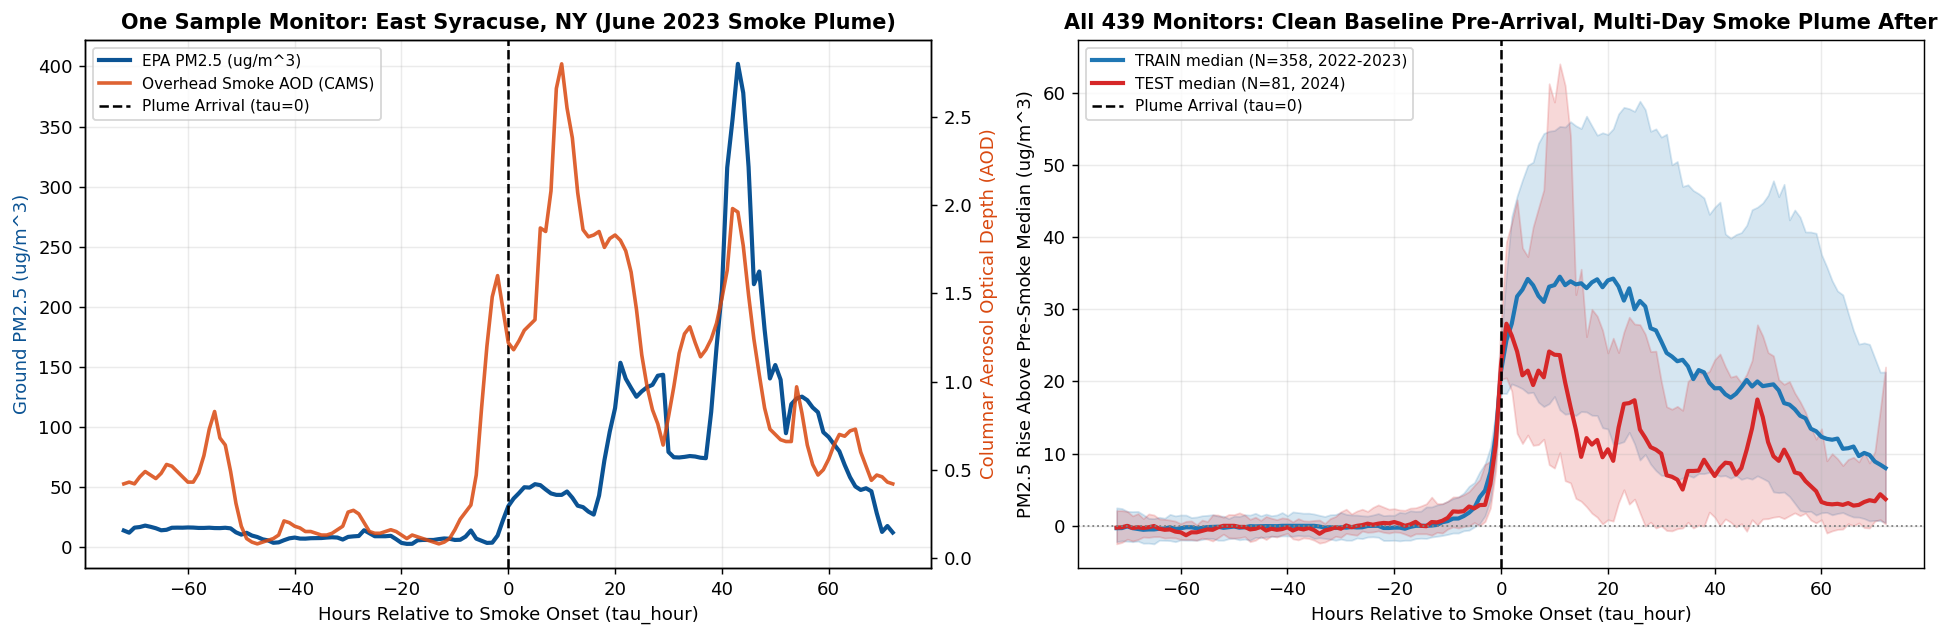

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=130)

# --- Left Panel: One Sample Monitor (East Syracuse, NY — June 2023 Canadian Megafire Plume) ---
ex_sid = meta[meta['site_id'] == '36-067-1015']['sample_id'].iloc[0]
ex = simple_df[simple_df['sample_id'] == ex_sid].sort_values('tau_hour')
ax1 = axes[0]
ax1_r = ax1.twinx()

l1, = ax1.plot(ex['tau_hour'], ex['pm25_ug_m3'], color='#0b5394', lw=2.3, label='EPA PM2.5 (ug/m^3)')
l2, = ax1_r.plot(ex['tau_hour'], ex['aerosol_optical_depth'], color='#d9480f', lw=2.0, alpha=0.85, label='Overhead Smoke AOD (CAMS)')
v1 = ax1.axvline(0, color='black', ls='--', lw=1.4, label='Plume Arrival (tau=0)')

ax1.set_title('One Sample Monitor: East Syracuse, NY (June 2023 Smoke Plume)', fontsize=11.5, fontweight='bold')
ax1.set_xlabel('Hours Relative to Smoke Onset (tau_hour)')
ax1.set_ylabel('Ground PM2.5 (ug/m^3)', color='#0b5394')
ax1_r.set_ylabel('Columnar Aerosol Optical Depth (AOD)', color='#d9480f')
ax1.grid(True, alpha=0.25)
ax1.legend([l1, l2, v1], [l1.get_label(), l2.get_label(), v1.get_label()], loc='upper left', fontsize=8.5)

# --- Right Panel: All 465 Stations — Excess PM2.5 Above Clean Pre-Onset Median ---
pre_med = simple_df[simple_df['tau_hour'] < 0].groupby('sample_id')['pm25_ug_m3'].median().rename('pre_med')
df_rel = simple_df.merge(pre_med, on='sample_id')
df_rel['rise_ug_m3'] = df_rel['pm25_ug_m3'] - df_rel['pre_med']

ax2 = axes[1]
n_tr = meta[meta['split'] == 'train'].shape[0]
n_te = meta[meta['split'] == 'test'].shape[0]
for split_name, color, label in [('train', '#1f77b4', f'TRAIN median (N={n_tr}, 2022-2023)'),
                                 ('test', '#d62728', f'TEST median (N={n_te}, 2024)')]:
    sub = df_rel[df_rel['split'] == split_name]
    stats = sub.groupby('tau_hour')['rise_ug_m3'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax2.plot(stats['tau_hour'], stats['med'], color=color, lw=2.3, label=label)
    ax2.fill_between(stats['tau_hour'], stats['q25'], stats['q75'], color=color, alpha=0.18)

ax2.axhline(0, color='gray', ls=':', lw=1.0)
ax2.axvline(0, color='black', ls='--', lw=1.4, label='Plume Arrival (tau=0)')
ax2.set_title(f'All {len(meta)} Monitors: Clean Baseline Pre-Arrival, Multi-Day Smoke Plume After', fontsize=11.5, fontweight='bold')
ax2.set_xlabel('Hours Relative to Smoke Onset (tau_hour)')
ax2.set_ylabel('PM2.5 Rise Above Pre-Smoke Median (ug/m^3)')
ax2.grid(True, alpha=0.25)
ax2.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.savefig('data/wildfire_smoke_simple_overview.png', dpi=150, bbox_inches='tight')
plt.show()